# Libraries

In [1]:
import pandas as pd
import numpy as np
import os
import tensorflow as tf
import cv2
from keras import backend as K
from keras.layers import Layer, InputSpec
import keras.layers as kl
from glob import glob
from sklearn.metrics import roc_curve, auc
from keras.preprocessing import image
from tensorflow.keras.models import Sequential
from sklearn.metrics import roc_auc_score
from tensorflow.keras import callbacks 
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from  matplotlib import pyplot as plt
from tensorflow.keras import Model
from tensorflow.keras.layers import concatenate, Dense, Conv2D, MaxPooling2D, Flatten, Input, Activation, add, AveragePooling2D, BatchNormalization, Dropout, GlobalAveragePooling2D, GlobalMaxPooling2D
%matplotlib inline
import shutil
from sklearn.metrics import  precision_score, recall_score, accuracy_score, classification_report, confusion_matrix
from tensorflow.python.platform import build_info as tf_build_info
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

2026-04-18 05:49:46.326416: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776491386.527594      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776491386.579398      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776491387.016578      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776491387.016625      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776491387.016628      55 computation_placer.cc:177] computation placer alr

In [2]:
targetnames = ['0_No_DR', '1_Mild_DR', '2_Moderate_DR', '3_Severe_DR', '4_Proliferative_DR']
batch_size = 16
image_size = 299

In [3]:
train_path = '/kaggle/input/datasets/humayratasnim/messidor-2-v-1-3/Messidor-2 1.3/train'
test_path = '/kaggle/input/datasets/humayratasnim/messidor-2-v-1-3/Messidor-2 1.3/test'
val_path = '/kaggle/input/datasets/humayratasnim/messidor-2-v-1-3/Messidor-2 1.3/val'

# Dataset generation (Train, Test, Validation)

In [4]:
datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.xception.preprocess_input)

In [5]:
print("\nTrain Batches: ")
train_batches = datagen.flow_from_directory(directory=train_path,
                                            target_size=(image_size,image_size),
                                            batch_size=batch_size,
                                            shuffle=True)

print("\nTest Batches: ")
test_batches = datagen.flow_from_directory(test_path,
                                          target_size=(image_size,image_size),
                                          batch_size=batch_size,
                                          shuffle=False)
print("\nVal Batches: ")
val_batches = datagen.flow_from_directory(val_path,
                                         target_size=(image_size,image_size),
                                         batch_size=batch_size,
                                         shuffle=False)


Train Batches: 
Found 17500 images belonging to 5 classes.

Test Batches: 
Found 348 images belonging to 5 classes.

Val Batches: 
Found 280 images belonging to 5 classes.


# Main Model Creation

### Squeeze and Excitation Attention

In [6]:
# def squeeze_excite_block(input, filters, se_ratio):
#     # Squeeze step
#     se = tf.keras.layers.GlobalAveragePooling2D()(input)
#     se = tf.keras.layers.Dense(filters // se_ratio, activation='relu')(se)
#     se = tf.keras.layers.Dense(filters, activation='softmax')(se)
#     # Excitation step
#     x = tf.keras.layers.multiply([input, se])
#     return x

### Define Model

In [7]:
from tensorflow.keras.applications.xception import Xception

X = Xception(weights='imagenet', include_top=False, input_shape=(image_size, image_size, 3), pooling='avg')

I0000 00:00:1776491417.360377      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Fine tuning

In [8]:
MainInput=Input(shape=(image_size, image_size, 3))

In [9]:
xception = X(MainInput)

In [10]:
# Reshape the tensor to have 4 dimensions
from tensorflow.keras.layers import Reshape
reshape = Reshape((16, 16, 8))(xception)

In [11]:
# Add convolutional layers with Channel Attention
conv = Conv2D(filters=128, kernel_size=(7, 7), activation="relu", padding="same", kernel_initializer='he_normal')(reshape)
conv = BatchNormalization()(conv)
conv = Conv2D(filters=128, kernel_size=(5, 5), activation="relu", padding="same", kernel_initializer='he_normal')(conv)
conv = BatchNormalization()(conv)
conv = Conv2D(filters=128, kernel_size=(3, 3), activation="relu", padding="same", kernel_initializer='he_normal')(conv)
conv = BatchNormalization()(conv)
conv = Conv2D(filters=128, kernel_size=(1, 1), activation="relu", padding="same", kernel_initializer='he_normal')(conv)
conv = BatchNormalization()(conv)

In [12]:
# image_size_2 = 16
# from tensorflow.keras.layers import Reshape
# conv = Reshape(target_shape=(image_size_2, image_size_2, 128,))(conv)
# x = squeeze_excite_block(conv, 128, 128)  # use same number of filters as the input tensor

In [13]:
# # Add convolutional layers with Channel Attention
# conv = Conv2D(filters=128, kernel_size=(7, 7), activation="relu", padding="same", kernel_initializer='he_normal')(x)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=128, kernel_size=(5, 5), activation="relu", padding="same", kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=128, kernel_size=(3, 3), activation="relu", padding="same", kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=128, kernel_size=(1, 1), activation="relu", padding="same", kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)

In [14]:
# conv=(MaxPooling2D(strides=(2, 2),padding="same")(conv))

In [15]:
# conv = Conv2D(filters=256,kernel_size=(7,7), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=256,kernel_size=(5,5), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=256,kernel_size=(3,3), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=256,kernel_size=(1,1), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)

In [16]:
# image_size_3 = 8
# from tensorflow.keras.layers import Reshape
# conv = Reshape(target_shape=(image_size_3, image_size_3, 256,))(conv)
# x = squeeze_excite_block(conv, 256, 256)  # use same number of filters as the input tensor

In [17]:
# conv = Conv2D(filters=256,kernel_size=(7,7), activation="relu",padding="same",kernel_initializer='he_normal')(x)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=256,kernel_size=(5,5), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=256,kernel_size=(3,3), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)
# conv = Conv2D(filters=256,kernel_size=(1,1), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
# conv = BatchNormalization()(conv)

In [18]:
# conv=(MaxPooling2D(pool_size=(2, 2),padding="same")(conv))

In [19]:
num_classes = test_batches.num_classes
print(num_classes)

5


In [20]:
conv=(Flatten()(conv))
conv=(Dense(1024,activation="relu")(conv))
conv = Dropout(0.35)(conv)
conv=(Dense(512,activation="relu")(conv))
conv = Dropout(0.25)(conv)
conv=(Dense(num_classes, activation="softmax")(conv))

model_x_sea = Model(inputs=MainInput, outputs=conv)

In [21]:
model_x_sea.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        50,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │    33,555,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,570,477 (211.98 MB)

 Trainable params: 55,514,925 (211.77 MB)

 Non-trainable params: 55,552 (217.00 KB)

In [22]:
opt1=tf.keras.optimizers.Adam(learning_rate=0.001,epsilon=0.1)
model_x_sea.compile(optimizer=opt1,
             loss='categorical_crossentropy',
             metrics=['accuracy'])

In [23]:
class_weights = {   
                    0: 1.0,   # 0_No_DR
                    1: 1.0,  # 1_Mild_DR
                    2: 1.0,  # 2_Moderate_DR
                    3: 1.0,  # 3_Severe_DR
                    4: 1.0,  # 4_Proliferative_DR
                }

In [24]:
checkpoint = ModelCheckpoint(filepath ='X_SEA.weights.h5', monitor='val_accuracy', save_best_only=True, save_weights_only=True)
Earlystop = EarlyStopping(monitor='val_accuracy', mode='max', patience=25, min_delta=0.01)

In [25]:
history = model_x_sea.fit(train_batches,
                         epochs=131,
                         verbose=2,
                         validation_data=val_batches,
                         callbacks=[checkpoint,Earlystop],
                         class_weight=class_weights)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/3


I0000 00:00:1776491446.222202     144 service.cc:152] XLA service 0x795720003d70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776491446.222247     144 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1776491450.796812     144 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-18 05:51:06.978481: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-18 05:51:07.188213: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-18 05:51:08.270524: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accur

1094/1094 - 441s - 403ms/step - accuracy: 0.6271 - loss: 0.9045 - val_accuracy: 0.7357 - val_loss: 0.6195
Epoch 2/3
1094/1094 - 273s - 249ms/step - accuracy: 0.8220 - loss: 0.4371 - val_accuracy: 0.7679 - val_loss: 0.5165
Epoch 3/3
1094/1094 - 273s - 249ms/step - accuracy: 0.9073 - loss: 0.2420 - val_accuracy: 0.8536 - val_loss: 0.3671


### Plotting accuracy and loss

Number of epochs trained: 3


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

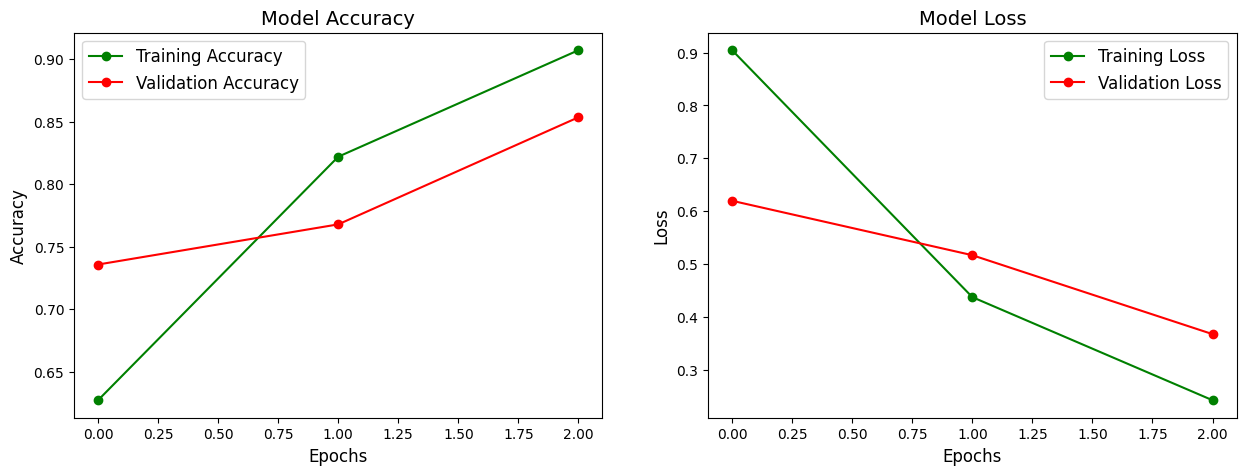

In [26]:
# Determine number of epochs trained
num_epochs_trained = len(history.history['val_loss'])
print(f"Number of epochs trained: {num_epochs_trained}")

## History plotting
epochs = [i for i in range(num_epochs_trained)]
fig , ax = plt.subplots(1,2)
train_acc = history.history['accuracy']
train_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']
fig.set_size_inches(15,5)

ax[0].plot(epochs , train_acc , 'go-' , label = 'Training Accuracy')
ax[0].plot(epochs , val_acc , 'ro-' , label = 'Validation Accuracy')
title_font = {'fontname':'Times New Roman', 'size':'14', 'color':'black', 'weight':'normal'}
ax[0].set_title('Model Accuracy', fontdict=title_font)
legend_font = {'family': 'Times New Roman', 'size': '12', 'weight': 'normal'}
ax[0].legend(prop=legend_font)
label_font = {'fontname':'Times New Roman', 'size':'12', 'color':'black', 'weight':'normal'}
ax[0].set_xlabel("Epochs",  fontdict=label_font)
ax[0].set_ylabel("Accuracy",  fontdict=label_font)

ax[1].plot(epochs , train_loss , 'g-o' , label = 'Training Loss')
ax[1].plot(epochs , val_loss , 'r-o' , label = 'Validation Loss')
ax[1].set_title('Model Loss', fontdict=title_font)
ax[1].legend(prop=legend_font)
ax[1].set_xlabel("Epochs", fontdict=label_font)
ax[1].set_ylabel("Loss", fontdict=label_font)
plt.show()

In [27]:
from tensorflow.keras import models
model_x_sea.load_weights("X_SEA.weights.h5")

In [28]:
predictions = model_x_sea.predict(test_batches)

22/22 ━━━━━━━━━━━━━━━━━━━━ 31s 861ms/step


In [29]:
#geting predictions on test dataset
y_pred = np.argmax(predictions, axis=1)
#getting the true labels per image 
y_true = test_batches.classes
#getting the predicted labels per image 
y_prob = predictions

In [30]:
classnames =  ['0_No_DR', '1_Mild_DR', '2_Moderate_DR', '3_Severe_DR', '4_Proliferative_DR']

from tensorflow.keras.utils import to_categorical
y_test = to_categorical(y_true)

report = classification_report(y_true, y_pred, target_names=classnames)

print("\nClassification Report:")
print(report)


Classification Report:
                    precision    recall  f1-score   support

           0_No_DR       0.99      0.96      0.97       203
         1_Mild_DR       0.88      0.96      0.92        54
     2_Moderate_DR       0.97      1.00      0.99        69
       3_Severe_DR       1.00      0.93      0.97        15
4_Proliferative_DR       1.00      1.00      1.00         7

          accuracy                           0.97       348
         macro avg       0.97      0.97      0.97       348
      weighted avg       0.97      0.97      0.97       348



findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


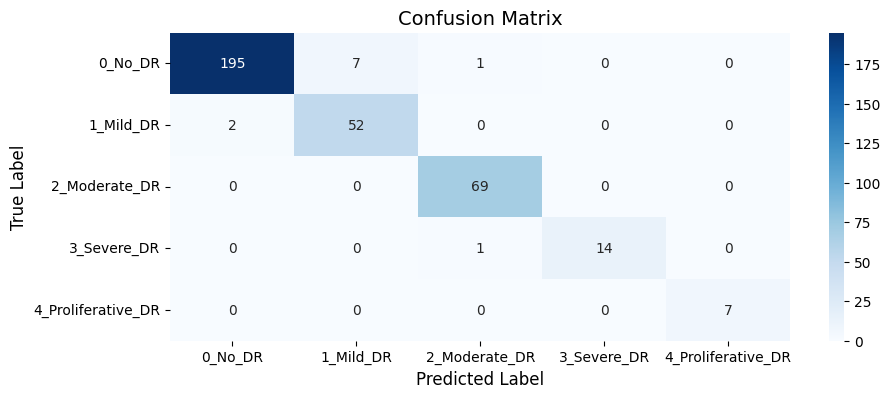

In [31]:
## Confusion Matrix
title_font = {'fontname':'Times New Roman', 'size':'14', 'color':'black', 'weight':'normal'}
label_font = {'fontname':'Times New Roman', 'size':'12', 'color':'black', 'weight':'normal'}

from sklearn.metrics import confusion_matrix
import seaborn as sns
# Creating confusion matrix 
cm = confusion_matrix(y_true, y_pred)
# Plotting the confusion matrix
plt.figure(figsize=(10,4))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=targetnames, yticklabels=targetnames)
plt.xlabel('Predicted Label', fontdict=label_font)
plt.ylabel('True Label', fontdict=label_font)
plt.title('Confusion Matrix', fontdict=title_font)
plt.show()

## Results

### Individual Class Accuracy 

In [32]:
# y_true are the true labels of the test set
# y_pred are the predicted labels of the test set
accuracy = accuracy_score(y_true, y_pred)
# Calculate accuracy for each class
class_accuracy = cm.diagonal()/cm.sum(axis=1)
print("Overall accuracy: {:.2f}%".format(accuracy*100))
print("Accuracy for each class:")
for i, acc in enumerate(class_accuracy):
    print("Class {}: {:.2f}%".format(i, acc*100))

Overall accuracy: 96.84%
Accuracy for each class:
Class 0: 96.06%
Class 1: 96.30%
Class 2: 100.00%
Class 3: 93.33%
Class 4: 100.00%


### Individual Class Weighted Precision

In [33]:
report = classification_report(y_true, y_pred, output_dict=True)
# Extract weighted precision for each class
class_precision = {}
for class_label in report.keys():
    if class_label == 'weighted avg':
        class_precision['weighted'] = report[class_label]['precision']
    elif class_label.isdigit():
        class_precision[int(class_label)] = report[class_label]['precision']
print("Weighted precision for each class:")
for i, precision in class_precision.items():
    if i == 'weighted':
        print("Weighted precision: {:.2f}%".format(precision*100))
    else:
        print("Class {}: {:.2f}%".format(i, precision*100))

Weighted precision for each class:
Class 0: 98.98%
Class 1: 88.14%
Class 2: 97.18%
Class 3: 100.00%
Class 4: 100.00%
Weighted precision: 97.01%


### Individual Class Weighted Recall

In [34]:
report = classification_report(y_true, y_pred, output_dict=True)
# Extract weighted recall for each class
class_recall = {}
for class_label in report.keys():
    if class_label == 'weighted avg':
        class_recall['weighted'] = report[class_label]['recall']
    elif class_label.isdigit():
        class_recall[int(class_label)] = report[class_label]['recall']
print("Weighted recall for each class:")
for i, recall in class_recall.items():
    if i == 'weighted':
        print("Weighted Recall: {:.2f}%".format(recall*100))
    else:
        print("Class {}: {:.2f}%".format(i, recall*100))

Weighted recall for each class:
Class 0: 96.06%
Class 1: 96.30%
Class 2: 100.00%
Class 3: 93.33%
Class 4: 100.00%
Weighted Recall: 96.84%


### Individual Class Weighted F1-score

In [35]:
report = classification_report(y_true, y_pred, output_dict=True)
# Extract weighted F1-score for each class
class_f1 = {}
for class_label in report.keys():
    if class_label == 'weighted avg':
        class_f1['weighted'] = report[class_label]['f1-score']
    elif class_label.isdigit():
        class_f1[int(class_label)] = report[class_label]['f1-score']
print("Weighted F1-score for each class:")
for i, f1_score in class_f1.items():
    if i == 'weighted':
        print("Weighted F1-score: {:.2f}%".format(f1_score*100))
    else:
        print("Class {}: {:.2f}%".format(i, f1_score*100))

Weighted F1-score for each class:
Class 0: 97.50%
Class 1: 92.04%
Class 2: 98.57%
Class 3: 96.55%
Class 4: 100.00%
Weighted F1-score: 96.87%


### Individual Class Precision, Recall and F1-score

In [36]:
from sklearn.metrics import precision_recall_fscore_support

precision_class, recall_class, f1_class, support_class = precision_recall_fscore_support(y_true, y_pred, average=None)
print('Class-wise weighted precision, recall, and F1-score:')
for i in range(len(precision_class)):
    print('Class {}: Precision={:.2f}, Recall={:.2f}, F1-score={:.2f}'.format(i, precision_class[i], recall_class[i], f1_class[i]))


Class-wise weighted precision, recall, and F1-score:
Class 0: Precision=0.99, Recall=0.96, F1-score=0.97
Class 1: Precision=0.88, Recall=0.96, F1-score=0.92
Class 2: Precision=0.97, Recall=1.00, F1-score=0.99
Class 3: Precision=1.00, Recall=0.93, F1-score=0.97
Class 4: Precision=1.00, Recall=1.00, F1-score=1.00


### Individual Class Weighted Sensitivity

In [37]:
from sklearn.metrics import recall_score

# Weighted Sensitivity = Weighted Recall
sensitivity = recall_score(y_true, y_pred, average='weighted')
print("Weighted Sensitivity: ", sensitivity)

# Class-wise Sensitivity = Recall per class
class_wise_sensitivity = recall_score(y_true, y_pred, average=None)

# Print sensitivity for each class
for i, score in enumerate(class_wise_sensitivity):
    print(f"Class {i}: sensitivity = {score}")

Weighted Sensitivity:  0.9683908045977011
Class 0: sensitivity = 0.9605911330049262
Class 1: sensitivity = 0.9629629629629629
Class 2: sensitivity = 1.0
Class 3: sensitivity = 0.9333333333333333
Class 4: sensitivity = 1.0


### Individual Class Weighted Specificity

In [38]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Confusion matrix: rows = actual, cols = predicted
cm = confusion_matrix(y_true, y_pred)
num_classes = cm.shape[0]

specificities = []
for i in range(num_classes):
    TN = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    FP = np.sum(np.delete(cm, i, axis=0)[:, i])
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    specificities.append(specificity)
    print(f"Class {i}: specificity = {specificity}")

# Weighted specificity
class_counts = np.bincount(y_true)
weighted_specificity = np.average(specificities, weights=class_counts)
print("Weighted Specificity:", weighted_specificity)

Class 0: specificity = 0.9862068965517241
Class 1: specificity = 0.9761904761904762
Class 2: specificity = 0.992831541218638
Class 3: specificity = 1.0
Class 4: specificity = 1.0
Weighted Specificity: 0.9868381093631371


### Accuracy

In [39]:
print("Accuracy: " + str(accuracy_score(y_true, y_pred)))
import numpy as np
from sklearn.metrics import accuracy_score

Accuracy: 0.9683908045977011


In [40]:
# Calculate top-1 accuracy
top1_acc = accuracy_score(y_true, y_pred)
print("Top-1 Accuracy:", top1_acc)

# Calculate top-2 accuracy
y_pred_top2 = np.argsort(-predictions, axis=1)[:, :2] # Get the top 2 predicted classes
top2_acc = np.mean(np.array([y_true[i] in y_pred_top2[i] for i in range(len(y_true))]))
print("Top-2 Accuracy:", top2_acc)

# Calculate top-3 accuracy
y_pred_top3 = np.argsort(-predictions, axis=1)[:, :3] # Get the top 3 predicted classes
top3_acc = np.mean(np.array([y_true[i] in y_pred_top3[i] for i in range(len(y_true))]))
print("Top-3 Accuracy:", top3_acc)
from sklearn.metrics import f1_score

Top-1 Accuracy: 0.9683908045977011
Top-2 Accuracy: 0.9971264367816092
Top-3 Accuracy: 1.0


### Weighted Evaluation Measures

In [41]:
# print("Weighted Precision: "+ str(precision_score(y_true, y_pred, average='weighted')))
# print("Weighted Recall: "+ str(recall_score(y_true, y_pred, average='weighted')))
# print("Weighted F1-Score: "+ str(f1_score(y_true, y_pred, average='weighted')))
# print("Weighted Sensitivity: "+ str(sensitivity_score(y_true, y_pred, average='weighted')))
# print("Weighted Specificity: "+ str(specificity_score(y_true, y_pred, average='weighted')))
# print("weighted Roc score: " + str(roc_auc_score(y_true,y_prob,multi_class='ovr',average='weighted')))

### Macro Evaluation Measures

In [42]:
# print("Micro Precision: "+ str(precision_score(y_true, y_pred, average='micro')))
# print("Micro Recall: "+ str(recall_score(y_true, y_pred, average='micro')))
# print("Micro F1-Score: "+ str(f1_score(y_true, y_pred, average='micro')))
# print("Micro Sensitivity: "+ str(sensitivity_score(y_true, y_pred, average='micro')))
# print("Micro Specificity: "+ str(specificity_score(y_true, y_pred, average='micro')))

### Micro Evaluation Measures

In [43]:
print("Micro Precision: "+ str(precision_score(y_true, y_pred, average='micro')))
print("Micro Recall: "+ str(recall_score(y_true, y_pred, average='micro')))
print("Micro F1-Score: "+ str(f1_score(y_true, y_pred, average='micro')))
print("Micro Sensitivity: "+ str(recall_score(y_true, y_pred, average='micro')))
print("Micro Specificity: "+ str(recall_score(y_true, y_pred, average='micro')))

Micro Precision: 0.9683908045977011
Micro Recall: 0.9683908045977011
Micro F1-Score: 0.9683908045977011
Micro Sensitivity: 0.9683908045977011
Micro Specificity: 0.9683908045977011


## ROC

### Compute ROC curve and ROC area for each class

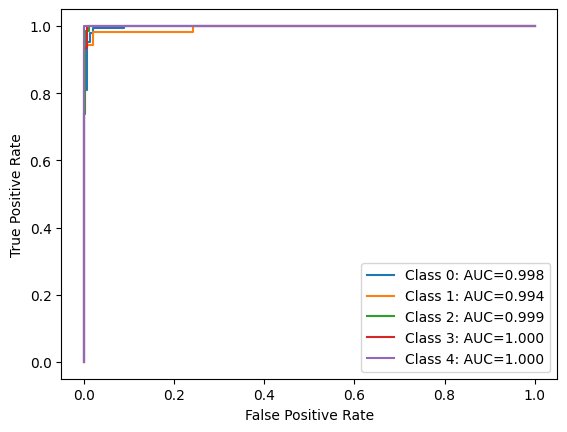

In [44]:
fpr = {}
tpr = {}
roc_auc = dict()
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_prob[:, i], drop_intermediate=False)
    roc_auc[i] = auc(fpr[i], tpr[i])


# plot the ROC curve for each class
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label='Class {}: AUC={:.3f}'.format(i, roc_auc[i]))

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()


## MCC and Kappa Score

In [45]:
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score

# y_true are the true labels of the test set
# y_pred are the predicted labels of the test set
mcc = matthews_corrcoef(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)
print("MCC: {:.2f}%".format(mcc*100))
print("Kappa Score: {:.2f}%".format(kappa*100))

MCC: 94.79%
Kappa Score: 94.74%


In [46]:
### Individual Class Wise MCC and Kappa

from sklearn.metrics import confusion_matrix, matthews_corrcoef, cohen_kappa_score
# y_true are the true labels of the test set
# y_pred are the predicted labels of the test set
conf_mat = confusion_matrix(y_true, y_pred)
mcc_per_class = {}
kappa_per_class = {}

for i in range(len(conf_mat)):
    tp = conf_mat[i][i]
    fp = sum(conf_mat[:, i]) - tp
    fn = sum(conf_mat[i, :]) - tp
    tn = sum(sum(conf_mat)) - tp - fp - fn

    mcc_per_class[i] = matthews_corrcoef([1 if x==i else 0 for x in y_true], [1 if x==i else 0 for x in y_pred])
    kappa_per_class[i] = cohen_kappa_score([1 if x==i else 0 for x in y_true], [1 if x==i else 0 for x in y_pred])

print("MCC per class:")
for i, mcc in mcc_per_class.items():
    print("Class {}: {:.2f}%".format(i, mcc*100))

print("Kappa Score per class:")
for i, kappa in kappa_per_class.items():
    print("Class {}: {:.2f}%".format(i, kappa*100))

MCC per class:
Class 0: 94.18%
Class 1: 90.62%
Class 2: 98.23%
Class 3: 96.46%
Class 4: 100.00%
Kappa Score per class:
Class 0: 94.12%
Class 1: 90.50%
Class 2: 98.21%
Class 3: 96.40%
Class 4: 100.00%
